### Build a Basic Chatbot with Langgraph (GRAPH API)

## LangGraph

- **LangGraph** is a framework for building stateful, multi-step AI agent workflows.
- Supports cycles, conditional routing, persistence, and human-in-the-loop interactions.
- Useful for complex agents and multi-agent systems.

## LangChain vs LangGraph

- **LangChain:** Provides components such as models, prompts, and tools for LLM applications.
- **LangGraph:** Orchestrates stateful, multi-step agent workflows.
- They can be used together.

#### LangGraph, there are two main APIs for defining workflows:  1. Graph API   2. Functional API

## Functional API

Defines workflows using ordinary Python functions and decorators.

- **`@entrypoint`** — Defines the workflow entry point.
- **`@task`** — Defines a task within the workflow.
- Supports persistence and resuming when configured appropriately.

## Graph API vs Functional API

| Graph API | Functional API |
|---|---|
| Explicit nodes and edges | Python functions and tasks |
| Best for complex branching and cycles | Best for straightforward Python workflows |
| State managed through graph state | Uses function inputs, outputs, and task results |

## Graph API

Defines workflows explicitly using nodes, edges and states.

### State Graph

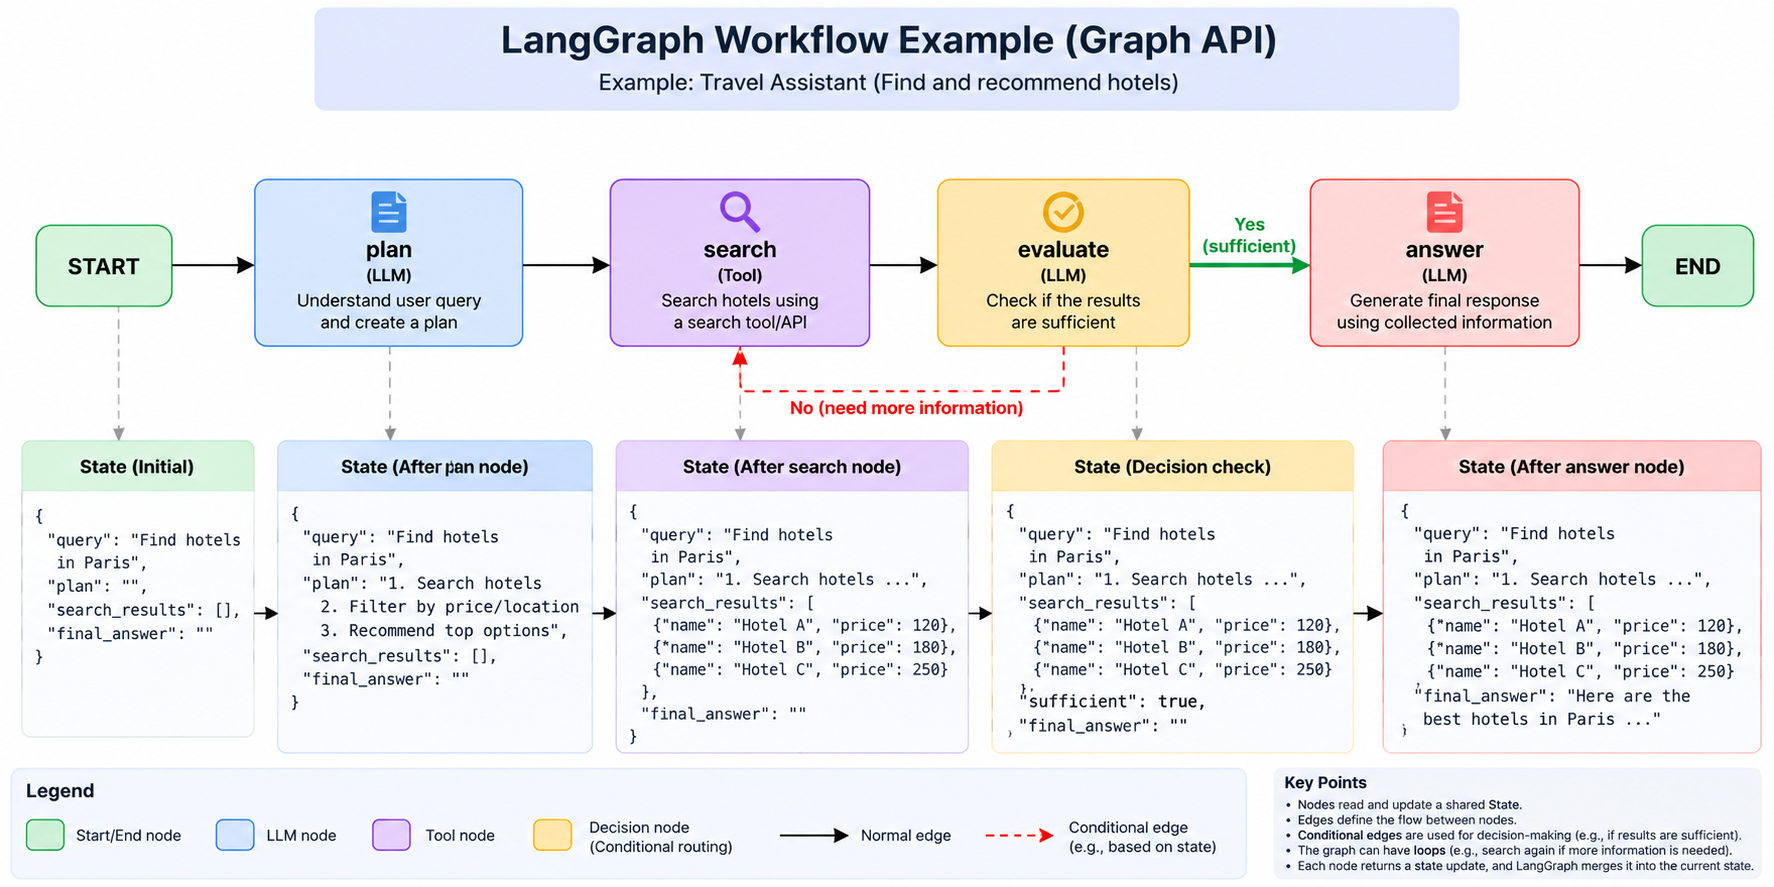
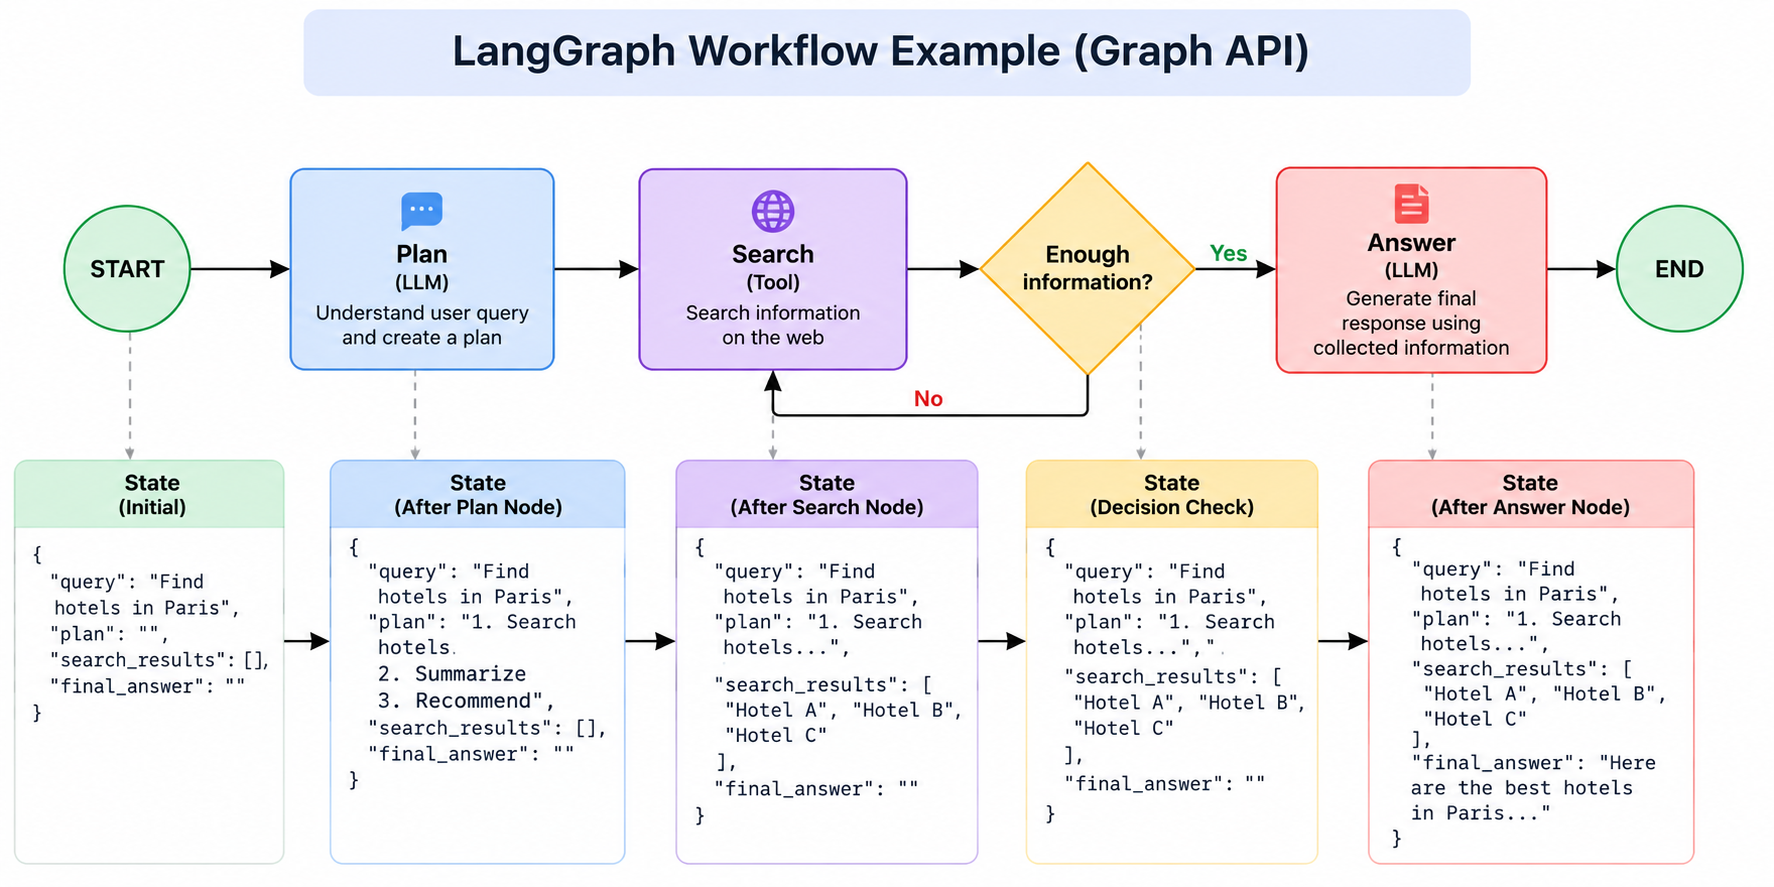

## StateGraph in LangGraph

- **StateGraph** is used to build workflows in LangGraph using nodes, edges, and shared state.
- **State:** Stores workflow data, such as the user query, plan, search results, and final answer.
- **Nodes:** Python functions that process the state and return updates.
- **Edges:** Define the execution flow between nodes.
- **Conditional Edges:** Route execution based on conditions or state values.
- **START:** Entry point of the workflow.
- **END:** Marks the completion of the workflow.
- **Checkpointer:** Saves state to support persistence and resuming workflows.
- **Compile:** Converts the graph definition into an executable workflow using `.compile()`.

### Workflow Example: Hotel Recommendation

1. **Plan node (LLM):** Understands the user's query and creates a search plan.
2. **Search node (Tool):** Searches for hotels and stores the results in the state.
3. **Evaluate node (LLM):** Checks whether the collected information is sufficient.
4. **Conditional routing:**
   - If sufficient → proceed to the Answer node.
   - If insufficient → return to the Search node for more information.
5. **Answer node (LLM):** Generates the final response using the collected information.
6. **END:** Workflow execution finishes.

### Key Points

- Nodes communicate through a shared state.
- Edges control the order of execution.
- Conditional edges enable decision-making and loops.
- State is updated as the workflow progresses.
- A checkpointer can save state for persistence and resuming execution.

## Basic LangGraph Workflow

- START: Entry point of the graph.
- Chatbot: A node that calls the LLM to generate a response.
- END: Marks the completion of the workflow.
Flow: START → Chatbot → END

This is a simple linear graph with one node and no conditional routing or loops.

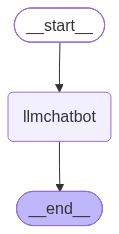

## Implementation

In [69]:
from typing import Annotated
from typing_extensions import TypedDict
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages  # reducers

## Reducers in LangGraph

- **Reducers** define how updates from nodes are merged with existing values of state keys.
- **Without a reducer:** The new value replaces the existing value by default.
- **With `operator.add`:** Lists are concatenated, appending new messages to existing messages rather than overwriting them.

In [70]:
class State(TypedDict):
    messages:Annotated[list,add_messages]   ## add messages to the list rather than overriding it

In [71]:
from dotenv import load_dotenv
import os
# load_dotenv(r"D:\GenAI\.env")
load_dotenv()

model = "openai/gpt-oss-120b"

In [72]:
from langchain_groq import ChatGroq
from langchain.chat_models import init_chat_model

llm=ChatGroq(model=model)

In [73]:
llm

ChatGroq(metadata={'lc_versions': {'langchain-core': '1.7.0', 'langchain': '1.4.7'}}, profile={'name': 'GPT OSS 120B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x000001E2D416AFD0>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x000001E2D416B9D0>, model_name='openai/gpt-oss-120b', model_kwargs={}, groq_api_key=SecretStr('**********'))

In [74]:
### Node functionality
def chatbot(state:State):
    return {"messages":[llm.invoke(state["messages"])]}

In [75]:
graph_builder = StateGraph(State)

# Adding node
graph_builder.add_node("llmchatbot",chatbot)
# Adding edge
graph_builder.add_edge(START,"llmchatbot")
graph_builder.add_edge("llmchatbot",END)

# Compile the graph
graph=graph_builder.compile()

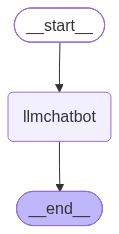

In [76]:
## Visulaize the graph
graph

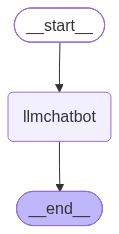

In [77]:
## Visulaize the graph
from IPython.display import Image,display

try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception:
    pass

In [78]:
response=graph.invoke({"messages":"Hi"})

In [79]:
response

{'messages': [HumanMessage(content='Hi', additional_kwargs={}, response_metadata={}, id='5fa16a03-ba09-4602-9d11-deaa33c0a5bd'),
  AIMessage(content='Hello! How can I assist you today?', additional_kwargs={'reasoning_content': 'The user just says "Hi". We need to respond appropriately, friendly greeting, perhaps ask how can help. No policy issues. So respond.'}, response_metadata={'token_usage': {'completion_tokens': 48, 'prompt_tokens': 72, 'total_tokens': 120, 'completion_time': 0.099370377, 'completion_tokens_details': {'reasoning_tokens': 30}, 'prompt_time': 0.004239635, 'prompt_tokens_details': None, 'queue_time': 0.32058773, 'total_time': 0.103610012}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_49bfac06f1', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a1896d-906b-709a-afce-dd953ba927e5-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 72, 'output_tokens': 48, 'total_tok

In [80]:
response["messages"]

[HumanMessage(content='Hi', additional_kwargs={}, response_metadata={}, id='5fa16a03-ba09-4602-9d11-deaa33c0a5bd'),
 AIMessage(content='Hello! How can I assist you today?', additional_kwargs={'reasoning_content': 'The user just says "Hi". We need to respond appropriately, friendly greeting, perhaps ask how can help. No policy issues. So respond.'}, response_metadata={'token_usage': {'completion_tokens': 48, 'prompt_tokens': 72, 'total_tokens': 120, 'completion_time': 0.099370377, 'completion_tokens_details': {'reasoning_tokens': 30}, 'prompt_time': 0.004239635, 'prompt_tokens_details': None, 'queue_time': 0.32058773, 'total_time': 0.103610012}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_49bfac06f1', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a1896d-906b-709a-afce-dd953ba927e5-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 72, 'output_tokens': 48, 'total_tokens': 120, 'ou

In [81]:
response["messages"][-1].content

'Hello! How can I assist you today?'

In [82]:
# Streaming
for event in graph.stream({"messages":"Hi, How are you?"}):
    for value in event.values():
        print(value["messages"][-1].content)

Hello! I'm doing great, thank you for asking. How can I assist you today?


## Chatbot with Tool -> TAVILY and CUSTOM Tools

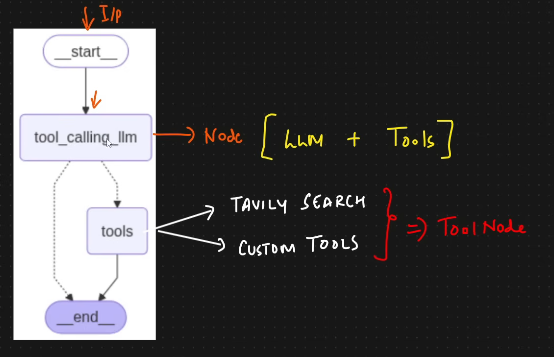
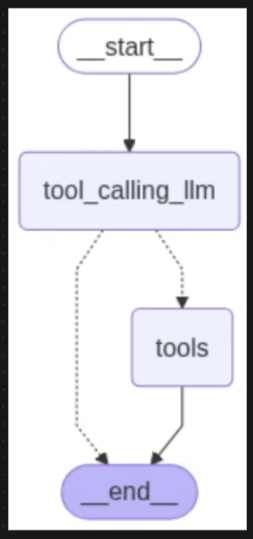

## Tool Calling in LangGraph

- **Tool Calling:** The LLM decides whether to call a tool based on the user's query.
- **Binding:** `bind_tools()` connects the LLM with the available tool definitions, allowing it to request tool calls.
- **Tool Calling Node:** Calls the LLM with the user input and bound tools.
- **Tool Node:** Executes the requested tool, such as Tavily Search or custom tools.
- **Flow:** `START → Tool Calling LLM → Tools → LLM → END`
- If no tool is required, the workflow can go directly from the LLM node to `END`.

**Important:** Binding makes tools available to the LLM; the `ToolNode` executes tool calls.

## Conditional Edges in LangGraph

- **Conditional edges** determine the next node based on a condition or the current state.
- They are commonly used for decision-making, tool routing, and loops.

**Example:** If the LLM requests a tool → `ToolNode`; otherwise → `END`.

**Key function:** `add_conditional_edges()`

In [83]:
from langchain_tavily import TavilySearch

tool = TavilySearch(max_results=2)
tool.invoke("What is langgraph")

{'query': 'What is langgraph',
 'follow_up_questions': None,
 'answer': None,
 'images': [],
 'results': [{'url': 'https://www.ibm.com/think/topics/langgraph',
   'title': 'What is LangGraph? | IBM',
   'content': 'LangGraph, created by LangChain, is an open source AI agent framework designed to build, deploy and manage complex generative AI agent workflows. It provides a set of tools and libraries that enable users to create, run and optimize large language models (LLMs) in a scalable and efficient manner. At its core, LangGraph uses the power of graph-based architectures to model and manage the intricate relationships between various components of an AI agent workflow. [...] Agent systems: LangGraph provides a framework for building agent-based systems, which can be used in applications such as robotics, autonomous vehicles or video games.\n\nLLM applications: By using LangGraph’s capabilities, developers can build more sophisticated AI models that learn and improve over time. Norweg

In [84]:
# Custom function
def multiply(a:int,b:int)->int:
    """Multiply a and b
    Args:
        a (int): first int
        b (int): second int
    Returns:
        int: output int
    """
    return a*b

In [85]:
tools=[tool,multiply]

In [86]:
llm_with_tools=llm.bind_tools(tools)

In [87]:
llm_with_tools

_ChatModelBinding(bound=ChatGroq(metadata={'lc_versions': {'langchain-core': '1.7.0', 'langchain': '1.4.7'}}, profile={'name': 'GPT OSS 120B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x000001E2D416AFD0>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x000001E2D416B9D0>, model_name='openai/gpt-oss-120b', model_kwargs={}, groq_api_key=SecretStr('**********')), kwargs={'tools': [{'type': 'function', 'function': {'name': 'tavily_search', 'description': 'A search engine optimized for comprehensive, accurate, an

In [88]:
# State Graph
from langgraph.graph import StateGraph,START,END 
from langgraph.prebuilt import ToolNode, tools_condition

# Node definition
def tool_calling_llm(state:State):
    return {"messages":[llm_with_tools.invoke(state["messages"])]}

# Graph

# Nodes
builder=StateGraph(State)
builder.add_node("tool_calling_llm",tool_calling_llm)
builder.add_node("tools",ToolNode(tools))

# Edges
builder.add_edge(START,"tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
    # If the latest message (result) from assistant is a tool call -> tools_condition routes to tools
    # If the latest message (result) from assistant is not a tool call -> tools_condition routes to END
    tools_condition
)
builder.add_edge("tools",END)

# Colmpile the graph
graph=builder.compile()

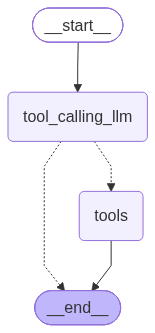

In [89]:
# Visualize
graph

In [90]:
# Request
response=graph.invoke({"messages":"Hi"})

In [91]:
response["messages"][-1].content

'Hello! How can I assist you today?'

In [92]:
response["messages"]

[HumanMessage(content='Hi', additional_kwargs={}, response_metadata={}, id='4babeb77-31fc-4801-b976-afa787ba0379'),
 AIMessage(content='Hello! How can I assist you today?', additional_kwargs={'reasoning_content': 'User says "Hi". Probably a greeting. We respond politely.'}, response_metadata={'token_usage': {'completion_tokens': 32, 'prompt_tokens': 366, 'total_tokens': 398, 'completion_time': 0.067822541, 'completion_tokens_details': {'reasoning_tokens': 14}, 'prompt_time': 0.015634049, 'prompt_tokens_details': None, 'queue_time': 0.208737248, 'total_time': 0.08345659}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_69334c0be3', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a1896d-9b01-71d6-9da4-636fcfbd5986-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 366, 'output_tokens': 32, 'total_tokens': 398, 'output_token_details': {'reasoning': 14}})]

In [93]:
response=graph.invoke({"messages":"What is the recent ai news?"})

In [94]:
response["messages"][-1].content

'{"query": "latest AI news October 2026", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://openai.com/index/building-scientific-understanding-with-academic-communities", "title": "Working with academic communities to build scientific understanding", "content": "We obtained our AI output on October 18th, 2026, which was formalized in Lean the following day, and then we reached out to an expert to discuss forming a collaboration around this result. Following their recommendation, we decided to release the AI output publicly, following the same strategy for this result as our October 6th, 2026 release\u2060. We have released both an AI natural language output writeup\u2060(opens in a new window) produced by our models and aLean proof \u2060(opens in a new window)in our public GitHub repository.\\n\\n## The Exponential Time Hypothesis is false [...] Our AI found its natural language disproof for the ETH on October 16th, 2026 and then subsequently we f

In [95]:
response["messages"]

[HumanMessage(content='What is the recent ai news?', additional_kwargs={}, response_metadata={}, id='7a551ffb-a868-40a7-9c71-ae608bef12ad'),
 AIMessage(content='', additional_kwargs={'reasoning_content': 'User asks: "What is the recent ai news?" They likely want a summary of recent AI news. Need up-to-date info. Use search tool with recent news. Let\'s search.', 'tool_calls': [{'id': 'fc_98b4cbad-bbe8-42a6-942c-b40f3d418122', 'function': {'arguments': '{"query":"latest AI news October 2026","search_depth":"advanced","time_range":"week","topic":"news"}', 'name': 'tavily_search'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 96, 'prompt_tokens': 372, 'total_tokens': 468, 'completion_time': 0.201863384, 'completion_tokens_details': {'reasoning_tokens': 38}, 'prompt_time': 0.054106175, 'prompt_tokens_details': None, 'queue_time': 0.349822509, 'total_time': 0.255969559}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_4200b3f836', 'service_ti

In [96]:
response=graph.invoke({"messages":"What is 29 multiplied by 6?"})

In [97]:
response["messages"][-1].content

'29\u202f×\u202f6\u202f=\u202f174.'

In [98]:
response["messages"]

[HumanMessage(content='What is 29 multiplied by 6?', additional_kwargs={}, response_metadata={}, id='6a2c02c4-29eb-4d70-b2fc-d1c6d184af86'),
 AIMessage(content='29\u202f×\u202f6\u202f=\u202f174.', additional_kwargs={'reasoning_content': 'The user asks "What is 29 multiplied by 6?" Simple multiplication. 29*6 = 174. No need to call any tool. Provide answer.'}, response_metadata={'token_usage': {'completion_tokens': 54, 'prompt_tokens': 374, 'total_tokens': 428, 'completion_time': 0.11167112, 'completion_tokens_details': {'reasoning_tokens': 35}, 'prompt_time': 0.009080804, 'prompt_tokens_details': {'cached_tokens': 256}, 'queue_time': 0.3507719, 'total_time': 0.120751924}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_dee443f41b', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a1896d-aae1-72d4-9cef-e02870e8bc72-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 374, 'output_tokens':

In [ ]:
response=graph.invoke({"messages":"What is the recent ai news and thenn multiply 4 by 3?"})

In [100]:
response["messages"][-1].content

'{"query": "latest AI news October 2026", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://llm-stats.com/llm-updates", "title": "AI Updates Today (October 2026) – Latest AI Model Releases", "content": "Quick verification\\n\\nConfirm you\'re human to keep going.\\n\\nNEW•NEW•NEW•NEW•\\n\\nThe AI arena is free today\\n\\nOpen Superagent\\n\\nAI NewsLLM UpdatesAI Trends\\n\\n# AI Updates Today\\n\\nAI model releases, version changes, API updates, and notable improvements across leading language models.\\n\\nLoading updates...\\n\\n Version Timeline\\n Quality Changes\\n Open Source\\n Organizations\\n API Providers\\n FAQ\\n\\nFollow us on\\n\\nLast 10\\n\\n## AI Model Releases\\n\\nTrack all LLM releases and version updates\\n\\nOct 19, 2026· 1 release\\n\\n### MiniMax M3.1 Flash\\n\\nLightweightProprietary\\n\\nMiniMax•1d ago\\n\\nOct 17, 2026· 1 release\\n\\n### DeepSeek-V4.1-Flash-1017\\n\\nFastOpen Source\\n\\nDeepSeek•3d ago\\n\\nOct 16, 2026·

In [101]:
response["messages"]

[HumanMessage(content='What is the recent ai news and thenn multiply 4 by 3?', additional_kwargs={}, response_metadata={}, id='1363db1c-3b36-425a-a060-986d1f16c6e0'),
 AIMessage(content='', additional_kwargs={'reasoning_content': 'The user asks: "What is the recent ai news and then multiply 4 by 3?" So we need to provide recent AI news (likely from current events) and also compute 4*3. We need to fetch recent AI news. Use the search tool. Let\'s search for recent AI news (maybe within last week).', 'tool_calls': [{'id': 'fc_b20cad9a-1966-4af1-83dc-7844badb8092', 'function': {'arguments': '{"query":"latest AI news October 2026","search_depth":"advanced","time_range":"week"}', 'name': 'tavily_search'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 119, 'prompt_tokens': 381, 'total_tokens': 500, 'completion_time': 0.253572036, 'completion_tokens_details': {'reasoning_tokens': 68}, 'prompt_time': 0.006511909, 'prompt_tokens_details': {'cached_tokens': 256},